# Q2: Edge Detection (10 points)
 Write a function that finds edge intensity and orientation in an image. Display the output of your function
 for one of the given images `uttower_left.JPG` and `uttower_right.JPG`
 `img1 = myEdgeFilter(img0, sigma)`

 The function will input a grayscale image (`img0`) and a scalar (`sigma`). Here, `sigma` is the standard
 deviation of the Gaussian smoothing kernel used before edge detection. The function should output
 `img1`, the edge magnitude image. First, use your convolution function to smooth the image with a
 Gaussian kernel defined by `sigma`. This step helps reduce noise and remove spurious edges. Use
 `scipy.signal.gaussian` to generate the Gaussian kernel. The filter size should depend on sigma
 (for example: `hsize = 2 ∗ ceil(3 ∗ sigma) + 1 )`

 Compute the edge magnitude image `img1` using gradients in both x and y directions. For the
 x-direction gradient (`imgx`), convolve the smoothed image with the x-oriented *Sobel filter*. For the
 y-direction gradient (`imgy`), convolve with the y-oriented Sobel filter. Combine these to obtain `img1`.
 Optionally, output `imgx` and `imgy` as well.

 Non-Maximum Suppression: Gradient magnitudes often produce thick edges. To thin them:
 - For each pixel, examine its two neighbors along the gradient direction.
 - If either neighbor has a larger gradient magnitude, suppress the current pixel (set its value to zero).
 - Quantize gradient orientation into four cases: 0◦, 45◦, 90◦, and 135◦. For example, an angle of 30◦ maps to 45◦.
 - The gradient angle can be computed as: theta = arctan(imgy/imgx)

 Restrictions: Your implementation must not call OpenCV’s Canny function or similar edge detectors.
 You may, however, use Canny for debugging or comparison purposes.

In [24]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal.windows import gaussian #forced to use this cuz scipy.signal.gaussian is replaced

### generating the gaussian kernel first

two kernels of sigma and sigma would give me a kernel of sigma*sqrt(2)

In [25]:
def gaussian_kernel(n, std):
    """Returns a nxn gaussian kernel"""
    std_temp = std/np.sqrt(2) #to fix the issue above

    gauss_1d = gaussian(n, std_temp)
    kernel = np.outer(gauss_1d, gauss_1d)
    kernel = kernel / np.sum(kernel) #normalisation
    return kernel

### Some other functions from q1 that are needed

In [26]:
def cross_correlation_2d(img, kernel, pad=True):
    """
    We do cross correlation with this func. using padding to decide if u want to have zero padding
    """
    img_h, img_w = img.shape
    kernel_h, kernel_w = kernel.shape

    if pad:
        pad_top_bot = kernel_h//2
        pad_left_right = kernel_w//2
        output_h, output_w = img_h, img_w
        img = np.pad(array=img,pad_width=(pad_top_bot, pad_left_right), constant_values=0)
    else:
        output_h, output_w = img_h - kernel_h+1, img_w-kernel_w+1
        
    output_img = np.zeros((output_h, output_w))

    for y in range(output_h):  #move down
        for x in range(output_w): #right
            img_piece = img[y:y+kernel_h, x:x+kernel_w]
            mult = np.multiply(img_piece, kernel)
            output_img[y][x] = np.sum(mult)
    
    return output_img

In [27]:
def convolve_2d(img, kernel, pad=True):
    impulse = np.zeros_like(kernel)
    kernel_h, kernel_w = kernel.shape
    impulse[kernel_h//2, kernel_w//2] = 1
    flipped_kernel = cross_correlation_2d(impulse, kernel, pad=True) #impulse is what my img is, need to have it samesize

    output_img = cross_correlation_2d(img, flipped_kernel, pad=pad)

    return output_img

## Now we write the actual edge filter with the help of these functions

In [28]:
def edge_filter(img0, sigma):
    size = int(2 *np.ceil(3*sigma) + 1)
    print("Kernel size: ", size)
    kernel = gaussian_kernel(size, sigma)

    blurred_img = convolve_2d(img0, kernel, pad=True)

    sobelx = np.array([
        [-1, 0, 1],
        [-2, 0, 2],
        [-1, 0, 1]
    ])#vertical edge

    sobely = np.array([
        [-1, -2, -1],
        [ 0,  0,  0],
        [ 1,  2,  1]
    ])#horizontal

    imgx = convolve_2d(blurred_img, sobelx, pad=True)
    imgy = convolve_2d(blurred_img, sobely, pad=True)
    
    plt.subplot(1, 2, 1)
    plt.imshow(imgx, cmap='gray')
    plt.subplot(1, 2, 2)
    plt.imshow(imgy, cmap='gray')
    plt.show()

    img1 = np.sqrt(imgx*imgx + imgy*imgy)
    return img1
     

### Testing this function out without non maximal suppression.

Kernel size:  7


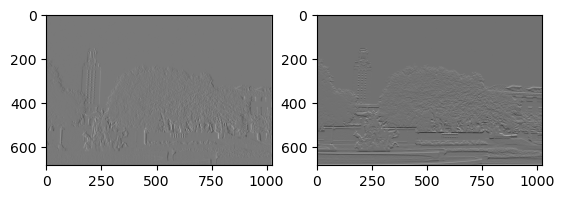

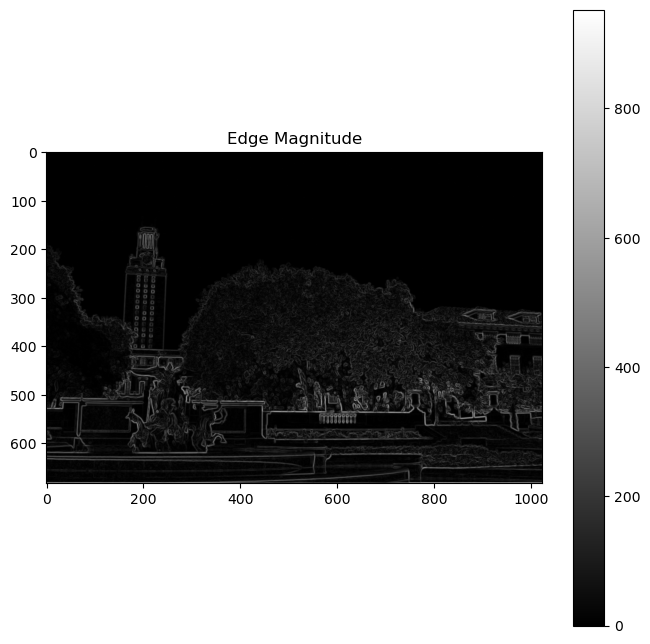

In [29]:
import matplotlib.pyplot as plt
import cv2

img = cv2.imread('uttower_left.JPG', cv2.IMREAD_GRAYSCALE)
img1= edge_filter(img, 1)

plt.figure(figsize=(8, 8))
plt.imshow(img1, cmap='gray')
plt.title("Edge Magnitude")
plt.colorbar()
plt.show()

### Redefining the edge filter functoin with the non maximal supression

In [34]:
def edge_filter(img0, sigma):
    size = int(2 *np.ceil(3*sigma) + 1)
    print("Kernel size: ", size)
    kernel = gaussian_kernel(size, sigma)

    blurred_img = convolve_2d(img0, kernel, pad=True)

    sobelx = np.array([
        [-1, 0, 1],
        [-2, 0, 2],
        [-1, 0, 1]
    ])#vertical edge

    sobely = np.array([
        [-1, -2, -1],
        [ 0,  0,  0],
        [ 1,  2,  1]
    ])#horizontal

    imgx = convolve_2d(blurred_img, sobelx, pad=True)
    imgy = convolve_2d(blurred_img, sobely, pad=True)
    
    plt.subplot(1, 2, 1)
    plt.imshow(imgx, cmap='gray')
    plt.subplot(1, 2, 2)
    plt.imshow(imgy, cmap='gray')
    plt.show()

    img1 = np.sqrt(imgx*imgx + imgy*imgy)


    # part where we apply non maximum supression
    gradiants = np.arctan2(imgy, imgx) #np using broadcast makes my life easy
    gradiants = np.degrees(gradiants)

    quantized_grads = np.zeros_like(gradiants)

    quantized_grads[ (gradiants > -22.5) & (gradiants <= 22.5) ] = 0
    quantized_grads[ (gradiants > 157.5) | (gradiants <= -157.5) ] = 0

    quantized_grads[ (gradiants > 22.5) & (gradiants <= 67.5) ] = 45
    quantized_grads[ (gradiants > -157.5) & (gradiants <= -112.5) ] = 45

    quantized_grads[ (gradiants > 67.5) & (gradiants <= 112.5) ] = 90
    quantized_grads[ (gradiants > -112.5) & (gradiants <= -67.5) ] = 90

    quantized_grads[ (gradiants > 112.5) & (gradiants <= 157.5) ] = 135
    quantized_grads[ (gradiants > -67.5) & (gradiants <= -22.5) ] = 135

    thinned_edges = np.zeros_like(img1)
    height, width = img1.shape

    for y in range(1, height - 1):
        for x in range(1, width - 1):
            angle = quantized_grads[y, x]
            magnitude = img1[y, x]

            
            if angle == 0: # Horizontal 
                neighbor_1, neighbor_2 = img1[y, x - 1], img1[y, x + 1]
                if magnitude >= neighbor_1 and magnitude >= neighbor_2: #we only keep the pixel whos val is greatest
                    thinned_edges[y, x] = magnitude
            elif angle == 45: # smth like y=x 
                neighbor_1, neighbor_2 = img1[y - 1, x + 1], img1[y + 1, x - 1]
                if magnitude >= neighbor_1 and magnitude >= neighbor_2: 
                    thinned_edges[y, x] = magnitude
            elif angle == 90: # vertical 
                neighbor_1, neighbor_2 = img1[y - 1, x], img1[y + 1, x]
                if magnitude >= neighbor_1 and magnitude >= neighbor_2: 
                    thinned_edges[y, x] = magnitude
            elif angle == 135: # y=-x direction
                neighbor_1, neighbor_2 = img1[y - 1, x - 1], img1[y + 1, x + 1]
                if magnitude >= neighbor_1 and magnitude >= neighbor_2: 
                    thinned_edges[y, x] = magnitude

    return thinned_edges

Kernel size:  13


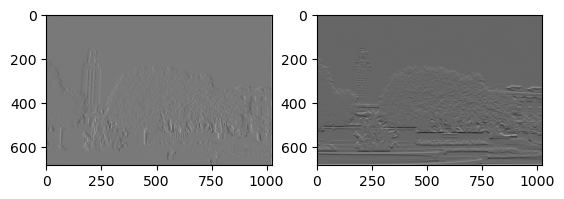

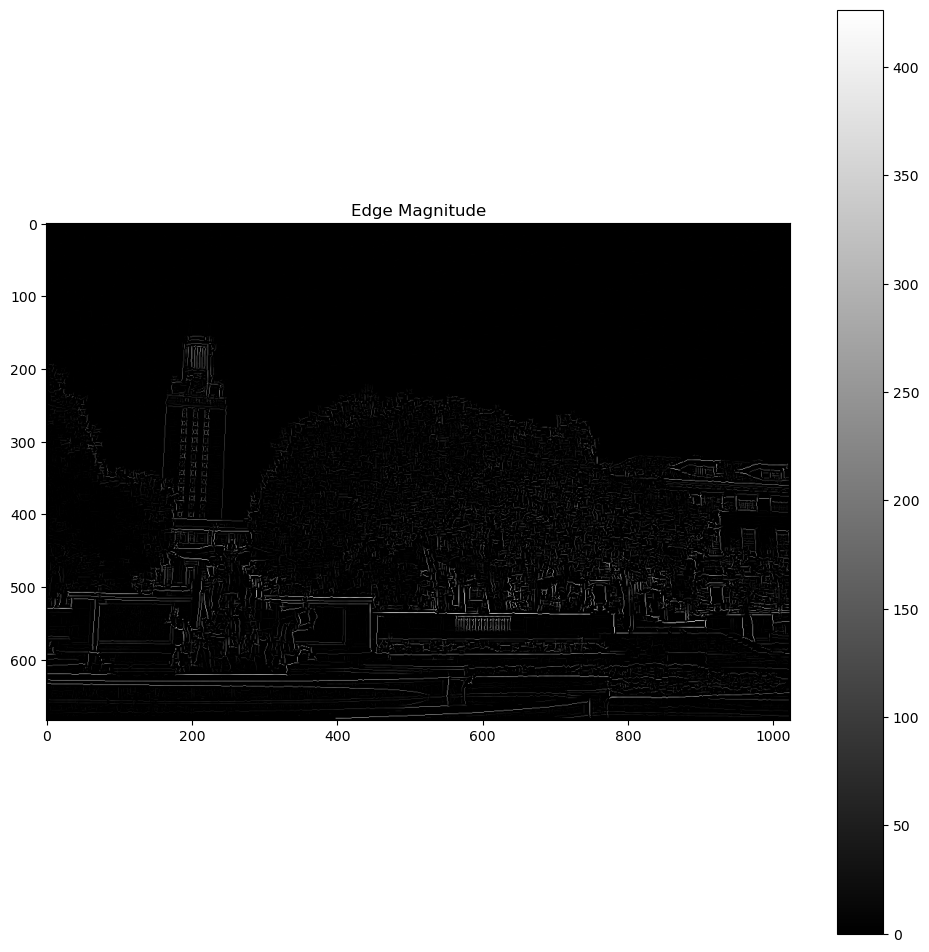

In [36]:
import matplotlib.pyplot as plt
import cv2

img = cv2.imread('uttower_left.JPG', cv2.IMREAD_GRAYSCALE)
img1= edge_filter(img, 2)

plt.figure(figsize=(12,12))
plt.imshow(img1, cmap='gray')
plt.title("Edge Magnitude")
plt.colorbar()
plt.show()